In [400]:
import numpy as np
import matplotlib.pyplot as plt
import time


<a id="build-world"></a>
# Build the hallway (the world)
The world is a hallway **3 rows by 8 columns**, and every cell is open: no walls inside, no pockets. Row 1 is the middle.

- The **robot** starts in the middle of the left end, `(1, 0)`, and its job is done when it reaches the **coffee machine**, the single cell `(1, 7)` in the middle of the right end.
- The **person** enters the middle row at a random column between 3 and 6 (`P_ENTRY_COLS`), picked at the start of each encounter, and walks left. They leave the hallway as soon as they reach **any** cell in column 0.

In [401]:
## setting up the world
ROWS, COLS = 3, 8
CELLS = [(row, col) for row in range(ROWS) for col in range(COLS)]

## the robot (doing the user's task) goes left -> right along the middle row
R_START = (1, 0)
R_GOAL = (1, 7)      

## the person enters the middle row at one of these columns, picked at random each encounter
P_ENTRY_COLS = [3, 4, 5, 6]
P_ROW = 1
## reaching any cell in column 0 means the person has left the hallway
P_GOAL_COL = 0

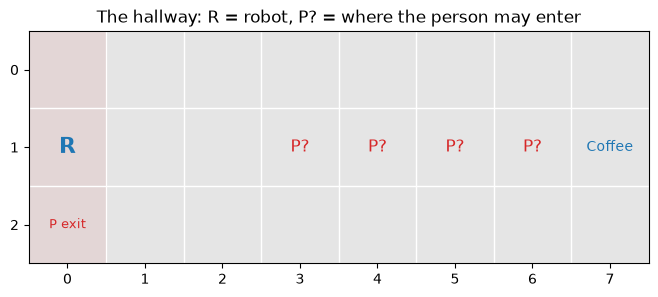

In [402]:
## draw an empty hallway; every cell is open, so it is one light-grey block with thin lines between cells
def draw_hallway(ax):
    ax.imshow(np.zeros((ROWS, COLS)), cmap="Greys", vmin=-0.3, vmax=1.3)
    ax.set_xticks(range(COLS))
    ax.set_yticks(range(ROWS))
    ax.set_xticks(np.arange(-0.5, COLS), minor=True)
    ax.set_yticks(np.arange(-0.5, ROWS), minor=True)
    ax.grid(which="minor", color="white", linewidth=1)
    ax.tick_params(which="minor", length=0)
    ## shade the person's exit column
    ax.axvspan(P_GOAL_COL - 0.5, P_GOAL_COL + 0.5, color="tab:red", alpha=0.08)

fig, ax = plt.subplots(figsize=(8, 3.2))
draw_hallway(ax)
ax.text(R_START[1], R_START[0], "R", ha="center", va="center", fontsize=16, color="tab:blue", weight="bold")
ax.text(R_GOAL[1], R_GOAL[0], "Coffee", ha="center", va="center", fontsize=10, color="tab:blue")
for col in P_ENTRY_COLS:
    ax.text(col, P_ROW, "P?", ha="center", va="center", fontsize=12, color="tab:red")
ax.text(P_GOAL_COL, 2, "P exit", ha="center", va="center", fontsize=9, color="tab:red")
ax.set_title("The hallway: R = robot, P? = where the person may enter")
plt.show()

<a id="states-actions"></a>
# States
A **state** $s$ has to describe everything that matters for what happens next: where the robot is and where the person is. However, when the non-user leaves the room, the robot's mission is not done yet, the episode only ends when the robot reaches the coffee (Goal)

what needed to be build in this section:
- `gone`: The non-users left the hallway
- `available cell for the non-users`
- `states`: **(robot position, person position)**

Give each one a number with `state_index`, so we can store values in a plain numpy array.

In [403]:
## When the non-user leave the room
GONE='gone' ## so their state is a literal string, which can't be on the grid

## The avaliable cell for the non-users can walk + the gone state
n_cells = []
for cell in CELLS:
  if cell[1] != P_GOAL_COL:
    n_cells.append(cell)
n_cells = n_cells + [GONE]

## a state is (robot position, person position); the two can never share a cell
states = []
for robot in CELLS: # For every cell the robot could be in
    for non_user in n_cells: # go through every position the non-user could be in (including "gone")
        if robot != non_user: # find all the combinations where they do not overlap
            states.append((robot, non_user)) # collect the remaining (robot, person) pairs into states.

## Make a dict and create a key for each states
state_index = {}
for i, s in enumerate(states): # enumerate(states) gives (index, (0,0)(0,1)) which then unpack into i and s.
    state_index[s] = i # the state has to be the key, because I want to look up a state and get back its number.

## state_index lets us store V(s) in a plain numpy array: V[state_index[s]]
state_index = {}
for i in range(len(states)):
    state_index[states[i]] = i

print(len(states), "states")
print(states[:3])

507 states
[((0, 0), (0, 1)), ((0, 0), (0, 2)), ((0, 0), (0, 3))]


In [404]:
## the robot reaching the door ends the encounter, so V = 0 there
def is_terminal(s):
    robot, person = s
    return robot == R_GOAL

n_terminal = 0
for s in states:
    if is_terminal(s):
        n_terminal += 1
print(n_terminal, "terminal states")

21 terminal states


<a id="states-actions"></a>
# **ACTION and MOVE**

Left and right are from each walker's **own** point of view. The robot faces the coffee machine (toward column 7), so its left is row 0. The person faces their exit (toward column 0), so their left is row 2. If both step to their own left, they end up in different rows and pass each other.

Robot:
- `to_left`: (-1, 0)
- `to_right`: (1, 0)
- `back`: (0, -1)
- `forward`: (0, 1)
- `Wait`: (0, 0)

Person:

- `Walk` (0, -1)
- `Stop` (0, 0)
- `to_left` (1, 0)
- `to_right` (-1, 0)

In [405]:
## the robot's actions; "wait" comes first, so when two actions are exactly as good, the robot waits
ACTIONS = {"wait": (0, 0), "to_left": (-1, 0), "to_right": (1, 0), "back": (0, -1), "forward": (0, 1)}
ACTION_SYMBOLS = {"to_left": "↑", "to_right": "↓", "back": "←", "forward": "→", "wait": "•"}   ## arrows as drawn on the map

## the person's moves: "walk" toward their goal, "stop" in place, or step "to_left" / "to_right" (their own left and right) to another row
PERSON_MOVES = {"walk": (0, -1), "stop": (0, 0), "to_left": (1, 0), "to_right": (-1, 0)}   ## the person faces column 0, so their left is row 2

ACTION_LIST, MOVE_LIST = list(ACTIONS), list(PERSON_MOVES)

<a id="one-step"></a>
# **One step: both move at once**
The robot and the non-user will have to **move at the same time**: each picks a move without seeing the other's move first. They may run into each other, and if both step to the same side, they're still in each other's way.

For that, we need to build two functions to compute where they land:

`n_target(non_user, move)`

- Takes the current cell of the non-user and move they pick
- check whether they are gone
- compute for where they land from this move
- if they land outside of the grid, stay put
- if they reach the goal, return gone
- else return the new cell

`r_target(robot, action)`

- Take the current cell of the robot and the action it picks
- compute for where they land from this move
- if it lands outside of the grid, stay put
- else return the new cell

In [406]:
def person_target (person, move):
  if person == GONE: ## check whether the person is already gone
    return person
  change_row, change_col = PERSON_MOVES [move]
  new_row = person[0] + change_row
  new_col = person[1] + change_col
  cell = (new_row, new_col)
  if cell not in CELLS:
    return person
  if cell[1] == P_GOAL_COL:
    return GONE
  else:
    return cell


In [407]:
def robot_target(robot, action):
    change_row, change_col = ACTIONS[action]
    new_row = robot[0] + change_row
    new_col = robot[1] + change_col
    cell = (new_row, new_col)
    if cell not in CELLS:
      return robot
    else:
      return cell

Now that we know how the both actors should move, we need to set up the outcome of all possible move for both party. 

1. `Task_reward` : the robot side of consequence of next action
2. `crowding`: the non-user's side of things: the burden counts that were caused by the robots


The **task layer** of the reward, $r_{\text{task}}$. It scores one step from the user's point of view, so it should be **more negative the longer the job takes**:

1. Every step costs time, so every step gets $-1$, **including wait** (waiting is not free for the user).
2. A **bump** (the robot tried to move but stayed put, because of a wall or the person) gets $-2$: it wasted a step and achieved nothing.
3. A **lane change** (moving `to_left` or `to_right`) gets $-3$. A wheeled robot has to turn, move over and straighten out, so changing lanes takes longer than driving straight. We call this cost `SIDESTEP_COST`.
4. Reaching the door gets $+10$.

In [408]:
SIDESTEP_COST = 3   ## a sideways move (changing lanes) takes the robot this many steps' worth of time

## the robot user's layer: -1 per step (waiting included), -2 for a bump, -SIDESTEP_COST for changing lanes, +10 for the door
def task_reward(robot, a, robot_next):
    if robot_next == R_GOAL:
        return 10
    if a != "wait" and robot_next == robot:   ## tried to move but stayed put
        return -2
    if a == "to_left" or a == "to_right":     ## changed lanes
        return -SIDESTEP_COST
    return -1

print("wait:", task_reward((1, 0), "wait", (1, 0)), "| bump:", task_reward((1, 0), "back", (1, 0)),
      "| change lanes:", task_reward((1, 0), "to_left", (0, 0)), "| forward:", task_reward((1, 0), "forward", (1, 1)),
      "| reach the coffee:", task_reward((1, 6), "forward", (1, 7)))

wait: -1 | bump: -2 | change lanes: -3 | forward: -1 | reach the coffee: 10


Now the **non-user layer**: the **crowding count** $c$ for one step. In this notebook $\theta$ is how much the person dislikes **yielding**, so $c$ counts exactly that:

$$c = \begin{cases} 1 & \text{if the person stepped to their left or right, out of the robot's way} \\ 0 & \text{otherwise} \end{cases}$$

Added up over an encounter, $c$ is the number of yields.

There is one more thing that can happen to the person: being **blocked**, meaning they tried to move but couldn't, because the robot was in the way. We record it as $b$, which is 1 in a step where the person was blocked and 0 otherwise. A person who chooses to stop is not blocked: they didn't try to move.

Blocking is the worst outcome for the person, so the robot pays a **fixed** penalty, `BLOCK_COST` $= 5$, every time it happens. The penalty is the same for every person and every $w$.

In [409]:
## the person's layer: c = 1 if the person stepped aside this step (the act of yielding), else 0
def crowding(person, move, person_next):
    c = 0
    if (move == "to_left" or move == "to_right") and person_next != person:
        c = 1
    return c

BLOCK_COST = 5   ## a fixed penalty each time the robot blocks the person, the same for every person and every w

## b = 1 if the person tried to move this step but couldn't, because the robot was in the way, else 0
def blocked(person, move, person_next):
    b = 0
    if person != GONE and move != "stop" and person_next == person:
        b = 1
    return b

Now we can put one step together. `step_outcome()` takes the robot's action $a$ and the person's move $m$ and works out:

1. **where they end up.** If both want the same cell, or they would walk *through* each other, it's a **clash** and neither moves.
2. $r_{\text{task}}$ for the robot's move.
3. $c$ (did the person yield?) and $b$ (was the person blocked?).

In [410]:
## both move AT THE SAME TIME: robot action a and person move m -> next state, r_task, c, b
def step_outcome(state, action, move):
    robot, person = state
    robot_next = robot_target(robot, action)
    person_next = person_target(person, move)

    ## clash: both want the same cell, or they would walk through each other -> neither moves
    if person_next != GONE:
        same_cell = robot_next == person_next
        swap = robot_next == person and person_next == robot
        if same_cell or swap:
            robot_next = robot
            person_next = person

    r_task = task_reward(robot, action, robot_next)
    c = crowding(person, move, person_next)
    b = blocked(person, move, person_next)
    return (robot_next, person_next), r_task, c, b

Let's check four situations. Each line prints `((robot next, person next), r_task, crowding, block)`.

In [411]:
## Test

print("blocked:                               ", step_outcome(((1, 2), (1, 4)), "forward", "walk"))

print("person swerves:                        ", step_outcome(((1, 2), (1, 4)), "forward", "to_right"))

print("robot swerves, person matching on:     ", step_outcome(((0, 3), (1, 4)), "forward", "walk"))

print("person stops, robot marching on:       ", step_outcome(((1, 3), (1, 4)), "forward", "stop"))

blocked:                                (((1, 2), (1, 4)), -2, 0, 1)
person swerves:                         (((1, 3), (0, 4)), -1, 1, 0)
robot swerves, person matching on:      (((0, 4), (1, 3)), -1, 0, 0)
person stops, robot marching on:        (((1, 3), (1, 4)), -2, 0, 0)


For every state, robot action and non-user move, we run `step_outcome` once and store what it returns (the next state, the task reward and the crowding parts) in big tables. We can do this because the result only depends on the state and the two moves.

- `NEXT[s, a, m]`: the index of the next state,
- `R_TASK[s, a, m]`: the task reward,
- `C_PARTS[s, a, m]`: the four crowding parts (and `C` = their weighted sum).

In [412]:
n_states, n_actions, n_moves = len(states), len(ACTION_LIST), len(MOVE_LIST)

## initiating empty arrays for each one of those
NEXT = np.zeros((n_states, n_actions, n_moves), dtype=int)   ## index of the next state
R_TASK = np.zeros((n_states, n_actions, n_moves))             ## task reward
C_PARTS = np.zeros((n_states, n_actions, n_moves, 3))         ## the four crowding parts
TERMINAL = np.array([is_terminal(s) for s in states])

But encounter can only happen when: 
- the non-user is still on the grid --> NOT GONE
- both are on the same row
- the robot is in front of (on the left of) the non-user i.e. the col of person > the col of robot

In [413]:
def in_the_way (s):
    robot, person = s
    return person != GONE and robot[0] == person[0] and robot[1] < person[1]

# Setting up the person
In each state, probablitity of them yielding to the robot

The person only has a decision to make when the robot is **in their way**: in the same row, somewhere ahead of them. Then distance ($d$) is how many columns apart they are. 

When the robot is in their way, what they do depends on their **type**:

**NOTE** 

ALthough I made 3 persona here, this Poc at the current state only use the average type as the main type so it doesn't become way too big for me to compute. But it will be incrediblely intersting to see how they differs in the end result. 

| type | when the robot is in their way |
|---|---|
| **accommodating** | someone who will give way to the robot early: 30% per step at $d = 5$, up to 75% at $d = 1$ |
| **average** | steps aside late: 20% at $d = 3$, 40% at $d = 2$, 60% at $d = 1$ |
| **stubborn** | rarely steps aside; they **stop** (70%) or march on to push the robot to go around |

Each type is a short table of "chance of yielding" and "chance of stopping" at each distance. Whatever is left over is the chance they keep walking. A stubborn person who has stopped still has a 10% chance per step of moving again (5–10% yield, the rest walk), so a standoff can't last forever.

In [414]:
BEHAVIORAL_PERSONA = {
    "accommodating": {"yield": {5: 0.3, 4: 0.4, 3: 0.6, 2: 0.8, 1: 0.9}, "stop": {}}, # there is no "stop" probability for the accommodating persona, because they will never stop in place
    "average":       {"yield": {3: 0.2, 2: 0.4, 1: 0.6},                 "stop": {}}, # same for the average persona, they will never stop in place
    "stubborn":      {"yield": {2: 0.3, 1: 0.4},                        "stop": {2: 0.7, 1: 0.6}}, # for they have a small chance of yielding, but most likely to stop if the robot doesn't make way. 
}

TYPE_NAMES = list(BEHAVIORAL_PERSONA)

However! People's overt behavior isn't also the same as their inner process (e.g., a person who is accommodating the robot doesn't necessarily mean they are not bother by doing so!) 

Here `theta` (0-10) measures how much they secretly dislike accommodating the robot, **$\theta$ = 0 means they barely care about accommodating the robot. $\theta$ = 10 means it really bothers them.**

`THETA_LEAK` is how much $\theta$ changes their yield chances. With `THETA_LEAK = 0`, people of the same type behave the same whatever their $\theta$. 

In [415]:
## THETA_LEAK set to 0 at default 

THETA_LEAK = 0.0

To know the actual probability of yielding behavior, which is factored by `THETA` and `THETA_LEAK`, we need a formula that represents the following:

- people who don't mind yielding at all ($\theta = 0$) follow the table exactly
- people who dislike yielding more (higher $\theta$) are less likely to yield
- disliking yielding can only **lower** the chance; nobody yields more than the table says

**Higher $\theta$ should decrease the probability of yielding**

**$\theta = 0$ (or `THETA_LEAK = 0`) should leave the table's chance unchanged**

**It's a NEGATIVE association**

We know each type's baseline chance of stepping aside from `BEHAVIORAL_PERSONA`. Now we build an expression that lets $\theta$ adjust it.


1. $-1 \times \dfrac{\theta}{10}$: rescale to the range −1 to 0. For example, $\theta = 0$ (doesn't care at all) gives 0, and $\theta = 10$ (really bothered by it) gives −1.

2. $\text{THETA\_LEAK} \times \left(-1 \times \dfrac{\theta}{10}\right)$: scale the effect by how strongly $\theta$ shows in behavior. With `THETA_LEAK = 0`, multiplying by 0 gives 0, so the person's inner feeling has no effect on the table's chance at all.

**However**, this expression will multiply the baseline chance, so "no change" can't be 0 (that would make the chance 0). It has to be 1, which leaves the baseline unchanged.

3. $1 + \text{THETA\_LEAK} \times \left(-1 \times \dfrac{\theta}{10}\right)$: turn the change into a multiplier, where 1 means no change.

4. $p_{\text{yield}} = \text{base}(d) \times \Big(1 + \text{THETA\_LEAK} \times \left(-1 \times \dfrac{\theta}{10}\right)\Big)$: apply it to the table's chance.



In [416]:
def theta_multiplier(theta, leak):
    shift = -1 * theta / 10      ## steps 1-2: rescale to -1 ... 0
    shift = leak * shift              ## step 3: scale by how strongly theta shows in behaviour
    multiplier = 1 + shift            ## step 4: turn it into a multiplier, where 1 means no change
    return multiplier

## steps 5-6: the chance of yielding and of stopping at distance d, for a person of this type
def yield_and_stop(type_name, d, multiplier):
    base_yield = BEHAVIORAL_PERSONA[type_name]["yield"].get(d, 0.0)   #.get is a dictionary method. It means “give me the value for key d, and if d isn’t a key, give me 0.0 instead.
    p_stop = BEHAVIORAL_PERSONA[type_name]["stop"].get(d, 0.0)
    p_yield = base_yield * multiplier                            
    p_yield = min(max(p_yield, 0.0), 1 - p_stop)        ## max(p_yield, 0.0) returns the larger of the two, so the result is never below 0. min(that, 1 - p_stop) returns the smaller of the two, so the result is never above 1 - p_stop.          
    return p_yield, p_stop

In [417]:
## an average person, robot 2 cells ahead (table chance 0.4), for a few theta and leak values
print(f"{'theta':>6} {'leak 0':>7} {'leak 0.5':>9} {'leak 1':>7}")
for theta in [0, 2.5, 5, 7.5, 10]:
    row = f"{theta:>6}"
    for leak in [0, 0.5, 1]:
        multiplier = theta_multiplier(theta, leak)
        p_yield, p_stop = yield_and_stop("average", 2, multiplier)
        row += f" {p_yield:>8.2f}"
    print(row)

 theta  leak 0  leak 0.5  leak 1
     0     0.40     0.40     0.40
   2.5     0.40     0.35     0.30
     5     0.40     0.30     0.20
   7.5     0.40     0.25     0.10
    10     0.40     0.20     0.00


**Discussion** Here, $\theta$ and LEAK are fixed per person, but in reality both may vary with context (e.g., LEAK may differ between an open road and a narrow hallway) and drift over time as people become familiar with robots. If contexts are observed, they can enter the model as features; if they arrive sequentially, continual learning is needed to adapt without forgetting earlier contexts.

### Where they step to
When the person yields from the middle row, they pick the top or the bottom row with a **coin flip**: 50/50. From an outer row, the only way to step aside is back to the middle.

`person_move_probs()` puts it all together for one state. It takes the person's type and multiplier. If the robot isn't in their way, they walk (or, once gone, stay gone).

In [418]:
## this function should take a state, the multiplier, and the type of person, and return a probability distribution over the person's moves

def person_move_probs(state, multiplier, type_name):
    robot, person = state
    if not in_the_way(state):
        return {"walk": 1.0, "stop": 0.0, "to_right": 0.0, "to_left": 0.0} ## the robot is not in the way, keep marchining on!!!
    
    ## get the distance needed for yield_and_stop function, which will give us the probability of yielding, stopping, and of course, walking. 
    distance = person [1] - robot[1]  
    p_yield, p_stop = yield_and_stop(type_name, distance, multiplier)
    probs = {"walk": 1 - p_yield - p_stop, "stop": p_stop} ## probs for walk and stop

    ## compute the probabilities for yielding and it's direction, depending on the person's row
    if person[0] == 1: ## the person is in the middle row, so they can step to their right (row 0) or their left (row 2)
        probs["to_right"] = p_yield / 2
        probs["to_left"] = p_yield / 2
    elif person[0] == 0: ## the person is in row 0, so they can only step to their left, back to the middle
        probs["to_left"] = p_yield
    else: ## the person is in row 2, so they can only step to their right, back to the middle
        probs["to_right"] = p_yield

    return probs

Let's meet p1! (Behavioral_Persona = `average`, $\theta$ = 5, `Leak` = 0) and how he interact with a hard compute robot

In [419]:
p1 = {"type_name": "average", "theta": 5.0, "leak": 0.0}

multiplier_p1 = theta_multiplier(p1["theta"], p1["leak"])

print(f"Multiplier for p1: {multiplier_p1}")

for state in [((1, 0), (1, 5)), ((1, 2), (1, 4)), ((1, 3), (1, 4)), ((0, 3), (1, 4))]:
    print(f"robot {state[0]}, p1 {state[1]}:", person_move_probs(state, multiplier_p1, p1["type_name"]))


Multiplier for p1: 1.0
robot (1, 0), p1 (1, 5): {'walk': 1.0, 'stop': 0.0, 'to_right': 0.0, 'to_left': 0.0}
robot (1, 2), p1 (1, 4): {'walk': 0.6, 'stop': 0.0, 'to_right': 0.2, 'to_left': 0.2}
robot (1, 3), p1 (1, 4): {'walk': 0.4, 'stop': 0.0, 'to_right': 0.3, 'to_left': 0.3}
robot (0, 3), p1 (1, 4): {'walk': 1.0, 'stop': 0.0, 'to_right': 0.0, 'to_left': 0.0}


See how each type of behavioral_persona behave in relationship to the distance between them and the robot

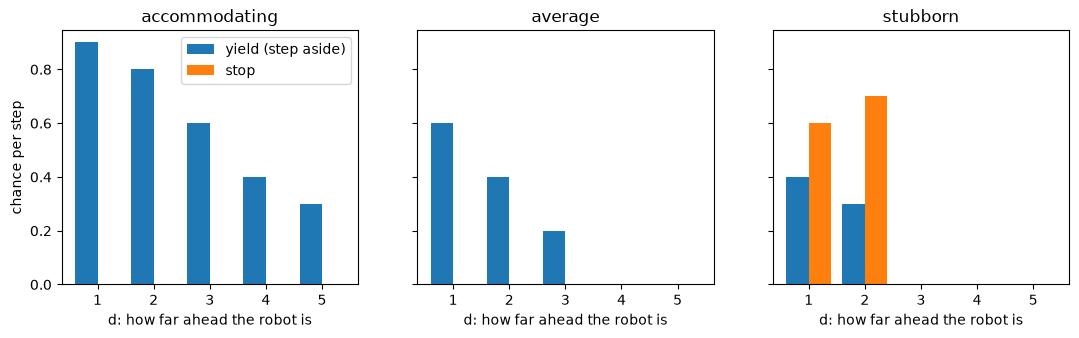

In [420]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
ds = [1, 2, 3, 4, 5]
type_names = list(BEHAVIORAL_PERSONA)
for i in range(3):
    ax = axes[i]
    yields, stops = [], []
    for d in ds:
        p_yield, p_stop = yield_and_stop(type_names[i], d, 1.0)   ## multiplier 1 = the table itself
        yields.append(p_yield)
        stops.append(p_stop)
    ax.bar(np.array(ds) - 0.2, yields, width=0.4, label="yield (step aside)")
    ax.bar(np.array(ds) + 0.2, stops, width=0.4, label="stop")
    ax.set_title(type_names[i])
    ax.set_xlabel("d: how far ahead the robot is")
    ax.set_xticks(ds)
axes[0].set_ylabel("chance per step")
axes[0].legend()
plt.show()

# Value iteration with any person
### Building the two-layer reward
We now have three scores for one step: $r_{\text{task}}$ for the robot (in units of time), $c$ for the person (did they yield?), and $b$ (were they blocked?). To plan, the robot needs **one** reward.

So the reward = the raw reward a robot get from performing an action at a state - how much this action cost to the co-presenting non-user. **EASY**

1. Start with plain task_reward $r_{\text{task}}$. Higher is better.
2. Crowding is bad for the non-user, so it should **lower** the score: subtract it, $r_{\text{task}} - c$.
3. But $c$ counts yields, and $r_{\text{task}}$ counts time. Subtracting them directly says "one yield is worth exactly one step of the user's time". It's a **VERY HARD** penalty, and it will probably be a good idea to add a weight to it so the exchange rate is adjustable.

$$r(s,a,s') = r_{\text{task}}(s,a,s') - w \cdot c(s,a,s')$$

$w$ is the **penalty weight**: how many steps of the user's time the robot is willing to spend to avoid one yield. With $w = 0$ the robot doesn't care about yields at all. With $w = 3$, causing one yield is as bad as 3 extra steps.

4. Last, blocking. It also lowers the score, by the fixed amount `BLOCK_COST` each time it happens, as a robot blocking the non-user is bad for itself and for the non-user. 

$$r(s,a,s') = r_{\text{task}}(s,a,s') - w \cdot c(s,a,s') - \text{BLOCK\_COST} \cdot b(s,a,s')$$

When the person isn't blocked, $b = 0$ and the last term drops out. When they are, $b = 1$ and the step costs an extra 5.

### Building the Bellman update

1. Suppose the person makes move $m$. Then we know exactly what happens to the robot: the robot lands in state $s'$ and get reward $r(s,a,s')$.
2. After that, the robot keeps acting well from $s'$. The **state value** $V(s')$ is how good it is to be in $s'$. A reward one step later counts a bit less, so we multiply it by the **discount factor** $\gamma = 0.95$. Taking action $a$ and then the person making move $m$ is worth $r(s,a,s') + \gamma V(s')$.
3. But we don't know which move the person will make. Each move $m$ has a chance, from the person's rule, and leads to one next state $s'$. Write $p(s' \mid s,a)$ for the chance of landing in $s'$. In plain language, Non-user's probability of going into a next state given the current state and robot's action at this time
4. So we take the **expected value**: multiply each outcome's worth by its chance, and add them up. This is the **action value**:

$$Q(s,a) = \sum_{s'} p(s' \mid s,a)\,\big[r(s,a,s') + \gamma V(s')\big]$$

5. The robot picks its best action, so the state's value is the best of these:

$$V(s) = \max_a Q(s,a)$$


### Precomputing the transitions

RL term: Transition function --> is one step from a state $s$ to a next state $s'$

`transitions(s, a, type_name, multiplier)` lists every possible result of action $a$ in state $s$: one `(next_state, r_task, c, b, move_probs[move], move)` for each move the person might make. It needs the person's type and multiplier, because those set the chances.

essentially, it's computing for this part: $\sum_{s'} p(s' \mid s,a)$

In [421]:
## for this function, we need to call the following
## 1. person_move_probs(state, multiplier, type_name) to get the probability distribution over the person's moves
## 2. step_outcome(state, action, move) to get the next state and the rewards for that move


def transitions(state, action, type_name, multiplier):
    outcomes = []

    ## get the probability distribution over the person's moves
    move_probs = person_move_probs(state, multiplier, type_name) # person_move_probs returns a dict of probabilities for each move. 

    for move in move_probs: # iterate through each move in the move_probs dictionary
        if move_probs[move] > 0: # if the probability of that move is greater than 0, then we can compute the outcome
            next_state, r_task, c, b = step_outcome(state, action, move) # compute the next state and the rewards for that move
            outcomes.append((move_probs[move],move, next_state, r_task, c, b)) # append the next state and the rewards to the outcomes list
    return outcomes

transitions(((1, 3), (1, 4)), "forward", "average", 1.0)

[(0.4, 'walk', ((1, 3), (1, 4)), -2, 0, 1),
 (0.3, 'to_right', ((1, 4), (0, 4)), -1, 1, 0),
 (0.3, 'to_left', ((1, 4), (2, 4)), -1, 1, 0)]

With the robot right in front of an average person (multiplier 1) and the robot moving forward, there are three possible results at this current state:

- 0.4: the person walks, they clash, the robot bumps and the person is blocked;
- 0.3: the person steps to their right (to row 0);
- 0.3: the person steps to their left (to row 2).

None of this depends on $w$, so we compute it **once** for every (state, action) pair, and store it in a dictionary `P`. Then value iteration can be re-run for any $w$ without redoing this work.

In [422]:
def build_transition_matrices(type_name, multiplier):
    P = {}
    for state in states: 
        if is_terminal(state):
            continue  # skip terminal states, as they have no transitions
        for action in ACTION_LIST:
            P[(state, action)] = transitions(state, action, type_name, multiplier)
    return P


Now `P` is tied to specfic person as need their type_name and multiplier, which is individualized. so here let's build a wrapper function to take those information from a person dictionary which will make later testing a lot easier.

Each entry should follow
`"person_name": {"type_name": , "theta": , "leak": }`

In [423]:
people = {
    "θ0 L0.25":   {"type_name": "average", "theta": 0.0,  "leak": 0.25},   ## 1.0
    "θ0 L0.5":    {"type_name": "average", "theta": 0.0,  "leak": 0.5},    ## 1.0
    "θ0 L1":      {"type_name": "average", "theta": 0.0,  "leak": 1.0},    ## 1.0

    "θ5 L0.25":   {"type_name": "average", "theta": 5.0,  "leak": 0.25},   ## 0.875
    "Average Joe":    {"type_name": "average", "theta": 5.0,  "leak": 0.5},    ## 0.75, calibration person
    "θ5 L1":      {"type_name": "average", "theta": 5.0,  "leak": 1.0},    ## 0.5

    "θ10 L0.25":  {"type_name": "average", "theta": 10.0, "leak": 0.25},   ## 0.75, same behavior as θ5 L0.5
    "θ10 L0.5":   {"type_name": "average", "theta": 10.0, "leak": 0.5},    ## 0.5, same behavior as θ5 L1
    "θ10 L1":     {"type_name": "average", "theta": 10.0, "leak": 1.0},    ## 0.0
}

cast = list(people.keys())

In [424]:
people

{'θ0 L0.25': {'type_name': 'average', 'theta': 0.0, 'leak': 0.25},
 'θ0 L0.5': {'type_name': 'average', 'theta': 0.0, 'leak': 0.5},
 'θ0 L1': {'type_name': 'average', 'theta': 0.0, 'leak': 1.0},
 'θ5 L0.25': {'type_name': 'average', 'theta': 5.0, 'leak': 0.25},
 'Average Joe': {'type_name': 'average', 'theta': 5.0, 'leak': 0.5},
 'θ5 L1': {'type_name': 'average', 'theta': 5.0, 'leak': 1.0},
 'θ10 L0.25': {'type_name': 'average', 'theta': 10.0, 'leak': 0.25},
 'θ10 L0.5': {'type_name': 'average', 'theta': 10.0, 'leak': 0.5},
 'θ10 L1': {'type_name': 'average', 'theta': 10.0, 'leak': 1.0}}

In [425]:
def build_P_for_person (person):
    multiplier = theta_multiplier(person["theta"], person["leak"])
    return build_transition_matrices(person["type_name"], multiplier)

In [426]:
P_tables = {name: build_P_for_person(person) for name, person in people.items()}

In [427]:
print(len(P_tables["Average Joe"]), " (state, action) pairs")


2430  (state, action) pairs


**Value Iteration** is just the Bellman equation turned into an algorithm: start with a guess for every square's value (we'll guess 0 everywhere), and keep applying the Bellman equation to every square, over and over, until the values stop changing. It's proven to always converge to the *true* optimal value function.

In [428]:
gamma = 0.95
tol = 1e-4

## Q(s,a) = sum over outcomes of prob * [ r_task - w*c - BLOCK_COST*b + gamma * V(s') ]
def Q_value (state, action, V, w, P_name):
    q = 0
    for prob, move, next_state, r_task, c, b in P_tables[P_name][(state, action)]:
        q += prob * (r_task - w*c - BLOCK_COST*b + gamma * V[state_index[next_state]])
    return q



def value_iteration(P_name, w):
    V = np.zeros(len(states))
    delta_history = []
    while True: # loop forever until delta < theta
        delta = 0 
        for state in states: 
            if is_terminal(state): 
                continue
            i = state_index[state] ## get the index of the state
            old_v = V[i] ## get the current value of the state
            best = -np.inf
            for action in ACTION_LIST: 
                q = Q_value(state, action, V, w, P_name) ## compute the Q value for the state and action
                if q > best:
                    best = q
            V[i] = best
            delta = max(delta, abs(old_v - V[i]))
        delta_history.append(delta) ## append the delta to the history
        if delta < tol: ## if the maximum change in value is less than the tolerance,
            break ## then we have converged, so we can break out of the loop
    return V, delta_history


both solved in 0.05 seconds
sweeps needed: w=0 -> 11, w=10 -> 12


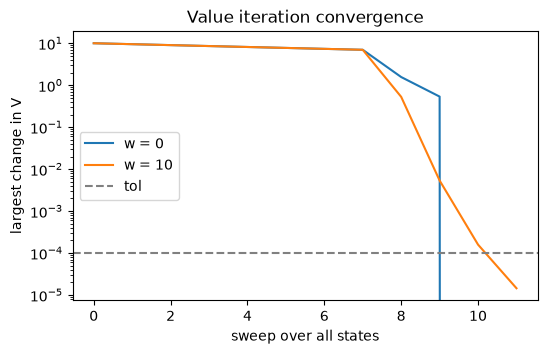

In [429]:
start = time.time()
V_w0, delta_w0 = value_iteration("Average Joe", 0)
V_w10, delta_w10 = value_iteration("Average Joe", 10)
print(f"both solved in {time.time() - start:.2f} seconds")
print(f"sweeps needed: w=0 -> {len(delta_w0)}, w=10 -> {len(delta_w10)}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(delta_w0, label="w = 0")
ax.plot(delta_w10, label="w = 10")
ax.axhline(tol, color="grey", linestyle="--", label="tol")
ax.set_yscale("log")
ax.set_xlabel("sweep over all states")
ax.set_ylabel("largest change in V")
ax.set_title("Value iteration convergence")
ax.legend()
plt.show()

In [430]:
s0 = (R_START, (P_ROW, 5))
print(f"V(start, person enters at column 5) with w = 0:  {V_w0[state_index[s0]]:.2f}")
print(f"V(start, person enters at column 5) with w = 10: {V_w10[state_index[s0]]:.2f}")

V(start, person enters at column 5) with w = 0:  -0.68
V(start, person enters at column 5) with w = 10: -2.10


When the robot doesn't care the non-user at all, the v value for its first step is -0.29

When all the robot ever care is avoiding the penalties that comes with causing the non-user yielding (-10), that plan costs it more time, and any yields it can’t avoid still cost 10 each. −2.10 is the best balance of those two costs.

<a id="policy"></a>
# Reading off and drawing the policy
A **policy** $\pi(s)$ says which action to take in each state. Once value iteration is done, the **optimal policy** $\pi^*$ just takes the action with the largest $Q$:

$$\pi^*(s) = \arg\max_a Q(s,a)$$

`extract_policy()` computes $Q(s,a)$ for every action and keeps the best one. It only switches to a later action if that one is **strictly** better, so ties go to `"wait"`.

In [431]:
## 1. it will use the V return from value_iteration to extract the optimal policy for each state.
## 2. it will use the person table to get the probability distribution of actions for each state
## ## pi*(s) = argmax over a of Q(s,a)
def extract_policy(V, w, P_name): 
    policy = {}
    for state in states: ## we want the optimal action for each state,
        if is_terminal(state): ## if the state is terminal, then there is no action to take
            continue
        best_action, best_q = None, -np.inf ## setting initial best q to negative infinity, so any q will be better than this
        for action in ACTION_LIST: ## iterate through all the actions
            q = Q_value(state, action, V, w, P_name)
            if q > best_q: ## if the q value for this action is better than the best q value so far,
                best_action, best_q = action, q ## and we update the best action and its q value
        policy[state] = best_action ## after iterating through all the actions, we store the best action for this state, indentation is important here, because we want to store the best action for each state, not just the last state we looked at
    return policy 

In [432]:
state0 = (R_START, (P_ROW, 5))

pi_w0 = extract_policy(V_w0, 0, "Average Joe")
pi_w10 = extract_policy(V_w10, 10, "Average Joe")

pi_w0[state0], pi_w10[state0]

('forward', 'to_left')

In [433]:
def plot_policy(pi, person_positions, title):
    fig, axes = plt.subplots(1, len(person_positions), figsize=(4.2 * len(person_positions), 2.2))
    for i in range(len(person_positions)):
        ax = axes[i]
        person = person_positions[i]
        draw_hallway(ax)
        ax.text(person[1], person[0], "P", ha="center", va="center", fontsize=16, color="tab:red", weight="bold")
        ax.text(R_GOAL[1], R_GOAL[0], "door", ha="center", va="center", fontsize=8, color="tab:blue")
        for robot in CELLS:
            s = (robot, person)
            if s in pi:
                ax.text(robot[1], robot[0], ACTION_SYMBOLS[pi[s]], ha="center", va="center", fontsize=15, color="tab:blue")
        ax.set_title(f"person at {person}", fontsize=10)
    fig.suptitle(title, y=1.05)
    plt.show()

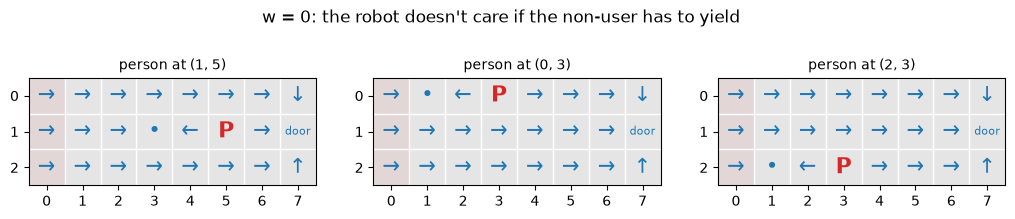

In [434]:
person_positions_to_show = [(1, 5), (0, 3), (2, 3)]
plot_policy(pi_w0, person_positions_to_show, "w = 0: the robot doesn't care if the non-user has to yield")

When the robot doesn't care if the non-user has to yield, the policy optimaze for two thing, try to avoid blocking (wait `•`, keeping one cell in between the non-user) and marching on to the target. It does not change its lane to get around the non-user. 

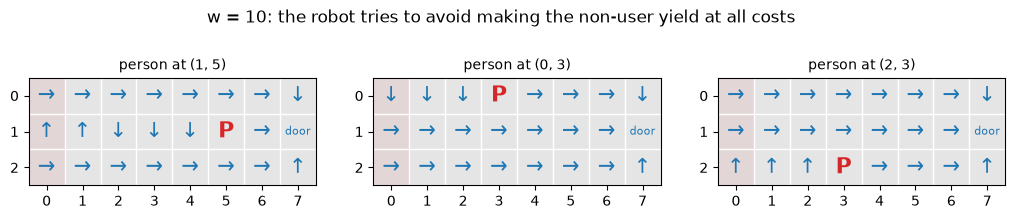

In [435]:
person_positions_to_show = [(1, 5), (0, 3), (2, 3)]
plot_policy(pi_w10, person_positions_to_show, "w = 10: the robot tries to avoid making the non-user yield at all costs")

When the robot tries to avoid making the person yield, it changes lanes as early as possible. The person's move depends on the state: they only consider stepping aside when `in_the_way` is true (the robot is in their row, ahead of them). By leaving the row early, the robot moves itself into states where `in_the_way` is false, so the person just keeps walking and never yields.

This almost seems like a good case for the non-user, as they don't need to bother with yielding to the robot. What if we take another perspective, which of the user of the robot, this policy means that it cost their task significantly just to make the non-user happy.... 

**Is it a really good w to set? what's the trade off** This has to be found out from (many times of) full encounter. 

# Simulating encounters
Value iteration gave us the robot's policy: its best action in every state, planned around what the non-user might do.

To simulate an encounter, we also need the non-user's actual move at each step. In this simulation the non-user isn't a learner: their move is random. At each step we **sample** one move, using the chances from `person_move_probs()`.

### How to pick one move
See each move's chance as an **interval**. Line the intervals up side by side so together they fill 0 to 1, with each interval as wide as its move's chance. Then draw one random number between 0 and 1: whichever interval it falls in is the move.

e.g. walk 0.4, stop 0.3, yield 0.3:

| move | interval |
|---|---|
| walk | 0 – 0.4 |
| stop | 0.4 – 0.7 |
| yield (left or right) | 0.7 – 1.0 |

A random number of 0.52 falls in stop's interval, so the non-user stops. Each interval is as wide as its chance, so each move is picked with exactly its own chance.

We wrap this in a small **environment**:

- `reset()` puts the robot at its start and the person at a random entry column, and returns that state.
- `env_step(s, a)` samples the person's move $m$, works out the step with `step_outcome()`, and returns `(s_next, m, r_task, c, b, done)`.

In [436]:
class HallwayEnv: 
    def __init__(self, person_name, seed):
        person = people[person_name]
        self.type_name = person["type_name"]
        self.multiplier = theta_multiplier(person["theta"], person["leak"])
        self.rng = np.random.default_rng(seed)  ## create a random number generator for this environment

    ## the non-user enters the hallway at a random column, and the robot starts at the left end of the middle row
    def reset(self):
        p_entry_col = int(self.rng.choice(P_ENTRY_COLS))  ## pick a random column for the non-user to enter
        return (R_START, (P_ROW, p_entry_col))  ## return the initial state

    ## sample a move for the non-user, given the current state and the robot's action
    def sample_move(self, state):
        probs = person_move_probs(state, self.multiplier, self.type_name)  ## get the probability distribution over the non-user's moves
        moves, probabilities = zip(*probs.items())  ## unzip the dictionary into two lists e.g., moves = ["walk", "stop", "to_right", "to_left"], probabilities = [0.5, 0.2, 0.2, 0.1]
        move = self.rng.choice(moves, p=probabilities)  ## sample a move from the list of moves, p=uses the probabilities as weights of drawing the moves
        return move  ## return the sampled move 

    ## using the sampled move, compute the next state and the rewards for that move
    def env_step(self, state, action): 
        move = self.sample_move(state)  ## sample a move for the non-user
        next_state, r_task, c, b = step_outcome(state, action, move)  ## compute the next state and the rewards for that move
        return move, next_state, r_task, c, b  ## return the next state and the rewards

**TEST with a w0 robot**

In [437]:
env = HallwayEnv("Average Joe", seed=42)
state = env.reset()
r_task_total, c_total, b_total = 0, 0, 0
print(f"initial state: robot at {state[0]}, person at {state[1]}")

for step in range(24): ## 24 is picked to be the maximum number of steps the robot can take to reach the goal. It could be anything larger than 7(R_steps in an empty hallway)
    
    ## ROBOT: get the optimal action for the current state
    action = pi_w0[state]

    
    ## NON-USER: sample their move; 
    # both move at once -> next state (robot, non-user), 
    # the robot's task reward, 
    # the non-user's yield (c)
    # blocked (b) counts   
    move, next_state, r_task, c, b = env.env_step(state, action)  
    
    print(f"step={step + 1}  robot {action}  person {move}  ->  robot={next_state[0]}  person={next_state[1]}  r_task={r_task}  c={c}  b={b}")
    r_task_total += r_task
    if is_terminal(next_state): ## if the next state is terminal, then we have reached the goal and can break out of the loop
        print(f"robot reached the goal! r task sum = {r_task_total}" )
        break
    state = next_state  ## update the current state to the next state for the next iteration

initial state: robot at (1, 0), person at (1, 3)
step=1  robot forward  person walk  ->  robot=(1, 1)  person=(1, 2)  r_task=-1  c=0  b=0
step=2  robot back  person to_left  ->  robot=(1, 0)  person=(2, 2)  r_task=-1  c=1  b=0
step=3  robot forward  person walk  ->  robot=(1, 1)  person=(2, 1)  r_task=-1  c=0  b=0
step=4  robot forward  person walk  ->  robot=(1, 2)  person=gone  r_task=-1  c=0  b=0
step=5  robot forward  person walk  ->  robot=(1, 3)  person=gone  r_task=-1  c=0  b=0
step=6  robot forward  person walk  ->  robot=(1, 4)  person=gone  r_task=-1  c=0  b=0
step=7  robot forward  person walk  ->  robot=(1, 5)  person=gone  r_task=-1  c=0  b=0
step=8  robot forward  person walk  ->  robot=(1, 6)  person=gone  r_task=-1  c=0  b=0
step=9  robot forward  person walk  ->  robot=(1, 7)  person=gone  r_task=10  c=0  b=0
robot reached the goal! r task sum = 2


<a id="measure"></a>
# Measuring encounters
To compare robots, we measure every encounter the same way. Everything later in the notebook uses these two costs.

**Cost to the user:** how much extra time the robot needed, compared with an empty hallway (7 steps). A lane change counts as `SIDESTEP_COST` = 3 steps of time, the same as in $r_{\text{task}}$.

**Cost to the person**, recorded in three pieces:

- **yields** $c$: how many times they stepped aside;
- **blocks**: how many times they were blocked;
- **delay**: how many extra steps they needed to leave, compared with walking straight out.

The person's **own cost** puts the pieces together with *their* $\theta^*$: they pay for their delay, and for every yield they pay $\theta^*$:

$$\text{person's own cost} = \text{delay} + \theta^* \times c$$

Blocks are not added separately: being blocked already shows up as delay.

## measure one encounter
`run_encounter(env, pi)` plays one encounter with a policy and returns the user cost, $c$, blocks and delay. It also returns **seen**: what the robot saw the person do. Every time the robot was in the person's way, it records the distance $d$ and the person's move. The learning robots in sections 12 and 13 learn from this. If the person is still in the hallway when the robot arrives, they walk the rest of the way alone, so their delay is complete.

In [438]:
EMPTY_ROBOT_STEPS = R_GOAL[1] - R_START[1]   

## run one encounter under policy pi: what it cost each side, and what the robot SAW the person do

def run_encounter(env, pi, max_steps=24):
    state = env.reset() ## initialize the environment and get the initial state
    entry_col = state[1][1] ## get the column where the non-user started

    ## initialize measurements: step, r_task_sum, r_time_steps, c_total, b_total, person_done_at(how many steps it took for the non-user to leave the hallway) 
    steps, robot_time_steps, c_total, b_total, person_done_at = 0, 0, 0, 0, None
    seen = [] ## initialize a list to keep track of what the robot saw the non-user do

    while not is_terminal(state) and steps < max_steps: 
        robot, person = state
        action = pi[state] ## get the optimal action for the current state
        move, next_state, r_task, c, b = env.env_step(state, action)
        steps += 1

        ## note the if robot had to turn sideways, and that's sidestep = 3, otherwise it's 1 step of time
        if action == "to_left" or action == "to_right":
            robot_time_steps += SIDESTEP_COST
        else:
            robot_time_steps += 1

        c_total += c
        b_total += b

        if in_the_way(state):
            seen.append((person[1]-robot[1], str(move))) ## if the robot was in the way, then we record what the non-user did

        ## check if the non-user has left the hallway, and if so, record how many steps it took
        if person_done_at is None and next_state[1]==GONE:
            person_done_at = steps
        
        ## don't forget to update the state for the next iteration
        state = next_state
    
    if person_done_at is None: 
        person_done_at = steps + state[1][1] ## if the robot finished the encounter before the non-user left, then we add the remaining distance to the exit to the steps taken so far

    return {
        'user_cost': robot_time_steps - EMPTY_ROBOT_STEPS, ## the total steps the robot take - what does it take if in a empty hallway = delay in time_step deliverying that coffee :(
        'C': c_total,
        'block': b_total,
        'non_user_delay': person_done_at - entry_col,
        'seen': seen
    }



In [439]:
env = HallwayEnv("Average Joe", seed=42)
print("w = 0: ", run_encounter(env, pi_w0))
env = HallwayEnv("Average Joe", seed=42)
print("w = 10:", run_encounter(env, pi_w10))

w = 0:  {'user_cost': 2, 'C': 1, 'block': 0, 'non_user_delay': 1, 'seen': [(3, 'walk'), (1, 'to_left')]}
w = 10: {'user_cost': 6, 'C': 0, 'block': 0, 'non_user_delay': 0, 'seen': [(3, 'walk')]}


## Measure n encounters!

Each line is one encounter: `user_cost`, `c`, `blocks` and `person_delay` as defined above, and `seen` as a list of `(d, move)` pairs.

To to compare policies we run many times and average. `run_many(pi, person_name, n, seed)` runs $n$ encounters and averages each measurement, and adds the person's own cost.

In [440]:
def run_multiple_encounters(pi, person_name, n, seed):
    env = HallwayEnv(person_name, seed)

    ## initializing the total

    totals = {'user_cost': 0.0, 'C': 0.0, 'block': 0.0, 'non_user_delay': 0.0}

    for i in range(n):
        result = run_encounter(env, pi)
        for key in totals: 
            totals[key] += result[key]
    averages = {}

    for key in totals: 
        averages[key] = totals[key]/n

    averages['non_user_cost'] = averages['non_user_delay'] + people[person_name]['theta'] * averages ['C']
    return averages

In [441]:
N_RUN = 300

for w, pi in [(0, pi_w0),(10, pi_w10)]:
    m = run_multiple_encounters(pi, "Average Joe", N_RUN, seed=42)
    print(f"w = {w:>2}: user_cost = {m['user_cost']:.2f}, C = {m['C']:.2f}, block = {m['block']:.2f}, "
          f"non_user_delay = {m['non_user_delay']:.2f}, non_user_cost = {m['non_user_cost']:.2f}")

w =  0: user_cost = 2.52, C = 0.83, block = 0.00, non_user_delay = 0.83, non_user_cost = 4.98
w = 10: user_cost = 6.02, C = 0.04, block = 0.00, non_user_delay = 0.04, non_user_cost = 0.26


# Robot toolkits

Before we go into building the robots, it will be good to have a set template of the robot. 

Each robot needs two things to run value iteration: a **$w$** and a **person to plan for** (a type and a multiplier). The four robots get them in different ways:

| robot | object in the code | $w$ | multiplier |
|---|---|---|---|
| **true naive** | `true_naive_robot` | fixed: `FIXED_W` | fixed: `NAIVE_MULTIPLIER`, the population average |
| **behavior-learning** | `behavior_robot` | fixed: `FIXED_W` | its posterior mean multiplier |
| **preference-learning** | `preference_robot` | its guess $\hat\theta$ | its expected multiplier |
| **oracle** | `oracle_robot` | the true $\theta^*$ | the true multiplier |

For that we need: `value_iteration()`, `extract_policy()`, `build_transition_matrices()` and `P_tables` from Value iteration with any person; `people` and `HallwayEnv` from Simulating encounters; `run_encounter()` from Measuring encounters.

This section will produce the `Robot` template that every robot section fills in.

In [442]:
## the same (w, multiplier) comes up again and again, so we build P and solve once, then reuse the policy
policy_cache = {}

In [443]:
def plan(w, multiplier, type_name="average"):
  ## later for the learning robots, the w and multiplier will be drifting every round e.g., 0.715, 0.722, 0.727, 
  ## instead of using all of them as the new w, round them up
  ## so that we can reuse the same policy for all w in the same 0.5 range, e.g., 0.5-1.0, 1.0-1.5, 1.5-2.0, etc.

    w = round(w * 2) / 2 ## round to the nearest 0.5
    multiplier = round(multiplier * 10)/10 ## round to the nearest 0.1, because it's fine enough to tell behaviors apart (range 0-1) but coarse enough to reuse cached P tables and policies

    P_name = f'{type_name}, multiplier {multiplier}' ## create a unique name for the policy based on the type of person and the multiplier

    # if the person is not in the P_tables yet, build the transition matrices for that person and store
    if P_name not in P_tables:
        P_tables[P_name] = build_transition_matrices(type_name, multiplier)
    key = (P_name, w) ## create a key for the policy cache based on the P_name and w

    # if the policy for this (P_name, w) is not in the cache, compute it and store it
    if key not in policy_cache: 
        V, _ = value_iteration(P_name, w) ## compute the valude for the p_name and w
        policy_cache[key] = extract_policy(V, w, P_name) ## extract the policy for the p_name and w

    return policy_cache[key]





### The Robot wrapper
Every robot does the same three things, in its own way:

1. **pick a plan:** at the start of each round, choose its $w$ and the multiplier to plan with;
2. **learn:** after each encounter, update what it believes from `seen` (the true naive robot and the oracle don't learn);
3. **forget:** before it meets a new person, start over.

The robot remembers what it learned; `reset` wipes that memory before it meets a new person. For the learning robots, `reset` copies their prior back in, so what they learned from one person (or one seed) never carries over to the next. The oracle's `reset` is where it is **told** the true person ($\theta^*$ and leak), which it needs to pick its plan. The true naive robot has nothing to forget, so its `reset` does nothing.

In [444]:
class Robot:
    def __init__(self, name, label, color, marker, pick_plan_rule, fixed_w=None,
                 prior=None, learn_rule=None, theta_rule=None, told_the_truth=False):
        ## how to draw this robot in the figures
        self.name = name
        self.label = label
        self.color = color
        self.marker = marker
       
       
       ## its rules; a function can be passed around and stored like any other value
        self.pick_plan_rule = pick_plan_rule   ## (robot) -> (w, multiplier)
        self.learn_rule = learn_rule           ## (belief, seen) -> new belief; None = never learns
        self.theta_rule = theta_rule           ## (belief) -> (guess of theta, SD); None = no guess of theta
        
        
        ## what it starts with
        self.fixed_w = fixed_w                 ## only the fixed-w robots use this
        self.prior = prior                     ## the starting belief; None = no belief
        self.told_the_truth = told_the_truth   ## True only for the oracle
        
        
        ## what it remembers; reset() sets these before every run
        self.belief = None
        #self.person = None

    ## forget everything learned before, and (oracle only) be told who the person is
    def reset(self, person):
        if self.prior is not None:
            self.belief = self.prior.copy()    ## .copy() makes a separate array, so the prior itself stays unchanged
        if self.told_the_truth:
            self.person = person

    ## step 1 of a round: the (w, multiplier) to plan with
    def pick_plan(self):
        return self.pick_plan_rule(self)       ## the rule gets the whole robot, so it can read its belief, fixed_w or person

    ## after each encounter: learn from what the robot saw
    def learn(self, seen):
        if self.learn_rule is not None:
            self.belief = self.learn_rule(self.belief, seen)

    ## the robot's guess of theta and its SD; NaN ("not a number") for robots that have no guess
        ## the robot's guess of theta and its SD; NaN ("not a number") for robots that have no guess
    def theta_guess(self):
        if self.theta_rule is None:
            return np.nan, np.nan
        return self.theta_rule(self.belief)

### Rounds
The robot meets the same person over and over, in **rounds**. Each round:

1. pick $w$ and the multiplier, with `robot.pick_plan()`;
2. solve for the policy with value iteration (cached, with `plan()`);
3. run 30 encounters with that policy; after each one, `robot.learn()` updates the robot's belief from what it saw;
4. record the round's averages, including the person's own cost (Measuring encounters).

We run **20 rounds of 30 encounters**. `run_rounds(person_name, robot)` takes any robot object. It calls `robot.reset()` first, so every run starts from scratch.

In [445]:
def run_rounds(person_name, robot, seed=0, n_rounds=20, n_encounters=30):
    person = people[person_name]
    env = HallwayEnv(person_name, seed)
    robot.reset(person)                        ## wipe what the robot learned before it meets this person
    theta_guess, theta_sd = robot.theta_guess()
    history = {"w": [], 
               "multiplier": [], 
               "theta_mean": [theta_guess], 
               "theta_sd": [theta_sd],
               "c": [], 
               "user_cost": [], 
               "non_user_cost": []}

    for round_number in range(n_rounds):
        ## 1. pick w and the multiplier to plan with
        w, multiplier = robot.pick_plan()
        ## 2. value iteration (cached)
        pi = plan(w, multiplier, person["type_name"])
        ## 3. run the encounters, and learn from what the robot saw
        c_total, user_total, person_total = 0.0, 0.0, 0.0
        for encounter in range(n_encounters):
            result = run_encounter(env, pi)
            c_total += result["C"]
            user_total += result["user_cost"]
            ## the person's own cost: their delay, plus theta* for every yield
            person_total += result["non_user_delay"] + person["theta"] * result["C"]
            robot.learn(result["seen"])
        ## 4. record this round's averages
        theta_guess, theta_sd = robot.theta_guess()
        history["w"].append(w)
        history["multiplier"].append(multiplier)
        history["theta_mean"].append(theta_guess)
        history["theta_sd"].append(theta_sd)
        history["c"].append(c_total / n_encounters)
        history["user_cost"].append(user_total / n_encounters)
        history["non_user_cost"].append(person_total / n_encounters)

    for key in history:
        history[key] = np.array(history[key])  ## turn each list into a numpy array, so we can use .mean() later
    return history

# LET'S BUILD THE ROBOTS !!!!

## TRUE_NAIVE

It learns nothing. It cares about the person with one fixed $w$ for everyone, and plans as if everyone behaves like the average person. So it needs two fixed numbers: a guess about behavior, and a $w$.

| robot | object in the code | $w$ | multiplier |
|---|---|---|---|
| **true naive** | `true_naive_robot` | fixed: `FIXED_W` | fixed: `AVERAGE_MULTIPLIER`, the population average |

### AVERAGE_MULTIPLIER
To know how an average person might behave, which is determined by the multiplier, which is controlled by θ and leak:

1. We need all the possible values of $\theta$ (0–10). In this case we assume an equal distribution with a 0.5 interval (0, 0.5, 1, …, 10; $n = 21$), so the chance of getting any single $\theta$ is $\frac{1}{21}$.

2. We also need all the possible values of leak (0–1). In this case we assume an equal distribution with a 0.2 interval (0.2, 0.4, 0.6, 0.8, 1; $n = 5$), so the chance of getting any single leak is $\frac{1}{5}$. We decided to not have leak = 0 because it will just mean the multiplier is always 1, no matter how big or small the $theta$ is, there is nothing for the robot to learn. 


In [446]:
## to do that, we need use np.arange(start, stop, step) makes an evenly spaced array; it stops BEFORE stop, so we use 10.01 to include 10

THETA_POPS = np.arange (0, 10.01, 0.5) 

LEAK_VALUES = [0.2, 0.4, 0.6, 0.8, 1.0] 
LEAK_CHANCES = [0.2, 0.2, 0.2, 0.2, 0.2] 

3. Each pair of $\theta$ and leak gives one multiplier by computing from `theta_multiplier()`, and the chance of getting any pair is $P(\theta) \times P(\text{leak}) = \frac{1}{21} \times \frac{1}{5} = \frac{1}{105}$.

4. There are $21 \times 5 = 105$ pairs, so 105 multipliers. We round each one to the nearest 0.05, so it matches the behavior robot's starting guess.

5. So to get the average multiplier:

$$\text{AVERAGE\_MULTIPLIER} = \frac{\text{sum of the 105 rounded multipliers}}{105}$$

or in expected value notation: average value = the sum of each single value times the chance of getting that value

$$\text{AVERAGE\_MULTIPLIER} = \sum_{\text{all 105 pairs}} \text{rounded multiplier} \times \text{pair's chance}$$

In [447]:
average_multiplier = 0.0

for theta in THETA_POPS: 
    for leak in range(len(LEAK_VALUES)):
        multiplier = theta_multiplier(theta, LEAK_VALUES[leak])
        rounded_multiplier = round(multiplier / 0.05) * 0.05
        pair_chance = (1/len(THETA_POPS)) * LEAK_CHANCES[leak] 
        average_multiplier += rounded_multiplier * pair_chance


print(f"AVERAGE_MULTIPLIER = {average_multiplier:.4f} (planned as {round(average_multiplier * 10) / 10})")

AVERAGE_MULTIPLIER = 0.7000 (planned as 0.7)


### Calibrating the fixed w (Figure 1)
The true naive robot and the behavior-learning robot are meant to be **reasonable robots**, so they shouldn't just ignore the cost to the non-users ($w$ = 0). So we need to pick a **reasonable fixed $w$ for everyone**.

The $w$ values we try are `[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]`.

Remember Average Joe?  That's our typical person with average $\theta$ (5) and average leak (0.5), which gives a multiplier of 0.75.
`AverageJoe = {"type_name": "average", "theta": 5.0, "leak": 0.5}`

The robot is told exactly how Joe behaves. We do this once, before comparing any robots, so the $w$ we pick isn't tuned to the comparison results.

In [448]:
multiplier_AverageJoe = theta_multiplier(people["Average Joe"]["theta"], people["Average Joe"]["leak"])

print(f"Multiplier for AverageJoe: {multiplier_AverageJoe:.4f}")

Multiplier for AverageJoe: 0.7500


For every $w$ in `[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]`:
1. solve the policy for that $w$
2. let the robot with this policy meet Joe 300 times (poor Joe)
3. record the averages: cost to the user (extra robot time per encounter) and cost to Joe (yields per encounter).

Every $w$ uses the same random seed, so Joe gets the same random luck in all 300 encounters for every $w$. Any difference between two $w$'s comes from the policy, not from random chance.


In [449]:
ws = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
sweeping_results = {}
for w in ws: 
    V, _ = value_iteration('Average Joe', w)
    pi = extract_policy(V, w, 'Average Joe')
    sweeping_results[w] = run_multiple_encounters(pi, 'Average Joe', N_RUN, seed=42)


print(f"{'w':>4} {'user_cost':>10} {'C':>6} {'block':>7} {'non_user_delay':>15}")
for w in ws: 
    m = sweeping_results[w]
    print(f"{w:>4} {m['user_cost']:>10.2f} {m['C']:>6.2f} {m['block']:>7.2f} {m['non_user_delay']:>15.2f}")

   w  user_cost      C   block  non_user_delay
   0       2.52   0.83    0.00            0.83
   1       2.52   0.83    0.00            0.83
   2       4.10   0.37    0.00            0.37
   3       4.98   0.18    0.00            0.18
   4       4.98   0.18    0.00            0.18
   5       6.02   0.04    0.00            0.04
   6       6.02   0.04    0.00            0.04
   7       6.02   0.04    0.00            0.04
   8       6.02   0.04    0.00            0.04
   9       6.02   0.04    0.00            0.04
  10       6.02   0.04    0.00            0.04


### Picking a reasonable w

It's definitely not a clean cut. So we pick the $w$ that gives the user the **best deal** while not giving the non-user a hard time: raising $w$ costs the user extra robot time, and in return Average Joe gives way less. We want to raise $w$ only while that trade is worth it.

For each step from one $w$ to the next:

1. **Extra user time** = user cost at the next $w$ − user cost at this $w$
2. **Yields removed** = yields at this $w$ − yields at the next $w$
3. **Rate** = yields removed ÷ extra user time, i.e. how many yields one unit of the user's time buys at this step

Steps where nothing changes (e.g. $w = 0 \to 1$) are skipped.

In [450]:
user_costs = [sweeping_results[w]['user_cost'] for w in ws]
yields     = [sweeping_results[w]['C'] for w in ws]

## for each step to the next w: yields removed per extra unit of user time
best_rate = 0.0
FIXED_W = ws[0]
for i in range(len(ws) - 1):
    extra_user_time = user_costs[i + 1] - user_costs[i]
    yields_removed = yields[i] - yields[i + 1]
    if extra_user_time <= 0:          ## nothing changed at this step (e.g. w 0 → 1), skip it
        continue
    rate = yields_removed / extra_user_time
    if rate > best_rate:
        best_rate = rate
        FIXED_W = ws[i + 1]           ## the w at the end of the best-value step

print(f"best deal: {best_rate:.2f} yields removed per extra unit of user time, so FIXED_W = {FIXED_W}")

best deal: 0.29 yields removed per extra unit of user time, so FIXED_W = 2


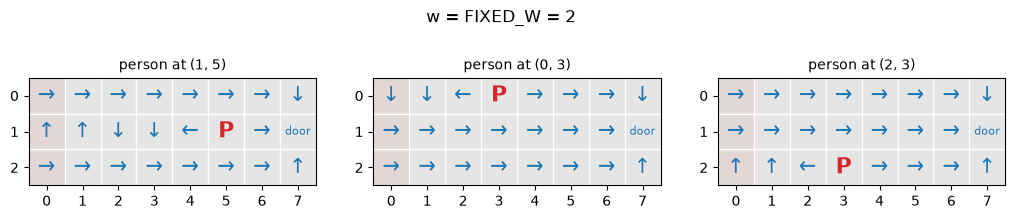

In [451]:
V_naive, _ = value_iteration("Average Joe", FIXED_W)
pi_naive_w = extract_policy(V_naive, FIXED_W, "Average Joe")
plot_policy(pi_naive_w, person_positions_to_show, f"w = FIXED_W = {FIXED_W}")

### The robot
Now we can fill in the `Robot` template from The robot toolkit. The true naive robot's rule for picking a plan always returns the same two numbers, `FIXED_W` and `NAIVE_MULTIPLIER`. It has no prior and no learning rule, so `reset` and `learn` do nothing.

In [452]:
## the true naive robot's rule: fixed w, fixed guess about behavior, whatever it has seen
def naive_pick_plan(robot):
    return robot.fixed_w, average_multiplier

true_naive_robot = Robot(name="naive", label=f"true naive (w = {FIXED_W})", color="tab:red", marker="v",
                         pick_plan_rule=naive_pick_plan, fixed_w=FIXED_W)

## a short sanity run: 3 rounds of 100 encounters with joe
check = run_rounds("Average Joe", true_naive_robot, n_rounds=3, n_encounters=100)
for i in range(3):
    print(f"round {i}: w = {check['w'][i]}, multiplier = {check['multiplier'][i]:.4f}, yields per encounter = {check['c'][i]:.2f}")

round 0: w = 2, multiplier = 0.7000, yields per encounter = 0.35
round 1: w = 2, multiplier = 0.7000, yields per encounter = 0.38
round 2: w = 2, multiplier = 0.7000, yields per encounter = 0.34


## Bayesian_behavior_inference

| robot | object in the code | $w$ | multiplier |
|---|---|---|---|
| **behavior-learning** | `behavior_robot` | fixed: `FIXED_W` | its posterior mean multiplier |

### Bayes' rule on a grid

The robot doesn't know this person's multiplier (how readily they yield). It needs a good guess so it can plan. It can't see the multiplier, but it can see the person's moves: walk, stop, or yield. So after every move, the robot updates how much it believes each possible multiplier.

**The grid: a fixed list of candidate multipliers**

The multiplier could be any number from 0 to 1. The robot can't check every number, so it only considers a fixed list of them, called the **candidates**. This list is the **grid**.

For each candidate, the robot keeps one probability: how much it believes that candidate is this person's multiplier. These probabilities are its **belief**, and they always add up to 1.

Example with 3 candidates. An average person (table yield chance 0.4) **yields** at $d = 2$:

| candidate multiplier | 0 | 0.5 | 1 |
|---|---|---|---|
| belief before the move | 1/3 | 1/3 | 1/3 |
| belief after the move | 0 | 1/3 | 2/3 |

The person yielded, so multiplier 0 ("never yields") is ruled out, and multiplier 1 gains the most belief.

**The update (Bayes' rule)**

$$P(x \mid m) = \frac{P(m \mid x)\, P(x)}{P(m)}$$

We work it out for **one** candidate multiplier $x$ and **one** move $m$. `bayes_update()` then does it for all candidates at once.

1. **Prior**, $\text{belief}(x)$ (written $P(x)$ in the formula): how much the robot believed $x$ before this move.
   - In the example: $1/3$ for every candidate.

2. **Likelihood**, $L(x)$ (written $P(m \mid x)$): if $x$ were this person's multiplier. The chances of the move the robot just saw came from `yield chance = table chance × multiplier.` The robot knows the table chance and guess $x$ is the multiplier. 
   - Yielded at $d = 2$: $L(x) = 0.4 \times x$. In the example: $L(0) = 0$, $L(0.5) = 0.2$, $L(1) = 0.4$.
   - Walked: $L(x) = 1 - \text{yield chance} - \text{stop chance}$.

3. **Multiply**: $\text{belief}(x) \times L(x)$ = the chance that $x$ is the multiplier **and** the chance of that move happens. Candidates that make the move more likely keep more belief.
   - In the example: $1/3 \times 0 = 0$, $1/3 \times 0.2 = 0.067$, $1/3 \times 0.4 = 0.133$.

4. **Rescale**: these numbers add up to 0.2, not 1. So we divide each one by their total. That total is $P(m)$, the overall chance of seeing this move.
   - In the example: $0 / 0.2 = 0$, $0.067 / 0.2 = 1/3$, $0.133 / 0.2 = 2/3$.

$$\text{new belief}(x) = \frac{\text{belief}(x) \times L(x)}{\text{sum over all candidates of } \text{belief} \times L}$$

The new belief is the **posterior**, $P(x \mid m)$: how much the robot believes each candidate after seeing move $m$. It becomes the prior for the next update, whether that's the next move in `seen` or the first move of the next encounter.

`bayes_update()` does steps 3 and 4: multiply the two arrays position by position, then divide by the total.

In [453]:
def bayes_update(belif, likelihood):
    new_belief = belif * likelihood
    return new_belief / new_belief.sum()

## LIKELIHOOD and BELIEF

To use bayes_update, we need two things

- likelihood

- Belief

### The likelihood of one move
The robot learns *whether* the person yielded, not which side they picked (that's a coin flip, the same for everyone). So we sort every move into three **categories**: walk, stop, or yield (`to_left` or `to_right`).

The likelihood of each category comes straight from `yield_and_stop()`:

- yielded: $p_{\text{yield}}$;
- stopped: $p_{\text{stop}}$;
- walked: whatever is left, $1 - p_{\text{yield}} - p_{\text{stop}}$.

Let's check it for an average person at $d = 2$ (table chance 0.4) with three multipliers.

In [454]:
## Translate To_left and To_right into a single "yield"

def move_category(move):
    if move == "to_left" or move == "to_right":
        return "yield"
    else:
        return move

def likelihood_of_move(d, multiplier, category, type_name): ## it should take d, multiplier, type_name for yield_and_stop, and category from move_to_yield
    p_yield, p_stop = yield_and_stop(type_name, d, multiplier) 
    if category == "yield": 
        return p_yield
    elif category == "stop":
        return p_stop
    p_walk = 1 - p_yield - p_stop
    return p_walk

In [455]:
for multiplier in [0.25, 0.5, 1.0]:
    print(f"multiplier {multiplier}: yield {likelihood_of_move(2, multiplier, 'yield', 'average'): .2f}, "
          f"walk {likelihood_of_move(2, multiplier, 'walk', 'average'):.2f}")

multiplier 0.25: yield  0.10, walk 0.90
multiplier 0.5: yield  0.20, walk 0.80
multiplier 1.0: yield  0.40, walk 0.60


### Its grid and prior

The behavior-learning robot only tracks one number: the multiplier. Its **candidate multipliers** are 0, 0.05, 0.1, …, 1 (21 values). The multiplier can't go above 1, because $1 - \text{leak} \times \frac{\theta}{10}$ is never more than 1.

To be fair, it should start with the same expectations as the other robots. So its prior is how common each candidate multiplier is in the population (the same population as the true naive robot's):

1. We need all the possible values of $\theta$ (0–10). We assume an equal distribution with a 0.5 interval (0, 0.5, 1, …, 10; $n = 21$), so the chance of getting any single $\theta$ is $\frac{1}{21}$.

2. We also need all the possible values of leak (0.2, 0.4, 0.6, 0.8, 1). Each leak's chance comes from `LEAK_CHANCE` (0.2 each).

3. Each pair of $\theta$ and leak gives one multiplier, from `theta_multiplier()`. The chance of getting any pair is $P(\theta) \times P(\text{leak}) = \frac{1}{21} \times 0.2$.

4. We round each pair's multiplier to the nearest 0.05. That's the **rounded multiplier**, and it is always one of the candidate multipliers.

5. For every pair, we add the pair's chance to its rounded multiplier's entry in the prior. Different pairs can have the same rounded multiplier, so their chances add up in the same entry.

At the end, the prior adds up to 1. Each candidate multiplier holds the chance that a random person's rounded multiplier is that candidate.

These are the same pairs and the same rounding as `NAIVE_MULTIPLIER`. So the average of this prior (each candidate multiplier × its chance, added up) equals `NAIVE_MULTIPLIER`. We check that below.

In [456]:
multiplier_grid = np.arange(0, 1.001, 0.05)

behavior_prior = np.zeros(len(multiplier_grid))

for theta in THETA_POPS:
    for leak_index in range(len(LEAK_VALUES)):
        multiplier = theta_multiplier(theta, LEAK_VALUES[leak_index])
        multiplier_index = int(round(multiplier / 0.05))
        behavior_prior[multiplier_index] += (1/len(THETA_POPS)) * LEAK_CHANCES[leak_index]

print(len(multiplier_grid), "multiplier values")
print(f"prior chance that the multiplier is exactly 1: {behavior_prior[20]:.2f}")

21 multiplier values
prior chance that the multiplier is exactly 1: 0.08


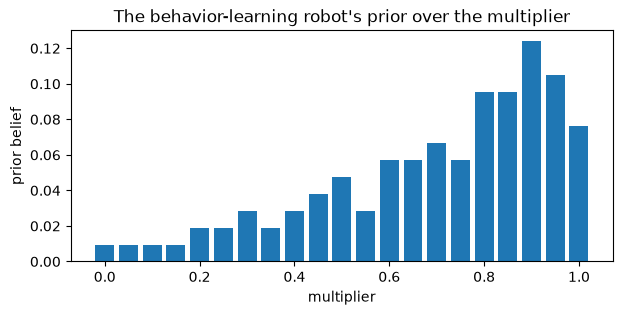

In [457]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(multiplier_grid, behavior_prior, width=0.04)
ax.set_xlabel("multiplier")
ax.set_ylabel("prior belief")
ax.set_title("The behavior-learning robot's prior over the multiplier")
plt.show()

Under our assumed population (θ and leak equally likely), about half of the (θ, leak) pairs give a rounded multiplier between 0.8 and 1, so before seeing anyone, the robot leans toward people who yield nearly as often as the table says.

It's reasonable to have higher chance near 0.8 - 1.0, the multiplier can only get low when both leak and $\theta$ are high, and if one of the get low, the multiplier will be high. That means the chance of a really low multiplier is roughly 1/4 of all combinations (only high θ + high leak), and the other 3/4 (high-low, low-high, low-low) give a high multiplier.

In other words, based on this assumed population, the robot is not likely to guess a low multiplier at the start. It expects the non-user to yield fairly often, so it may yield (sidestep) less often itself.

**DISCUSSION POINT**

Part of the reason the prior leans toward high multipliers is how we assumed leak and $\theta$ are distributed in the population. For the simplicity of the build, we assume both are equally distributed, meaning that the chance of any pair is $\frac{1}{21} \times 0.2 = \frac{1}{105}$. However, the distribution in a real human population might be very messy, and I hypothesize that $\theta$ will likely be skewed toward both ends, meaning many non-users either don't mind yielding at all or strongly dislike it. It will be an interesting thing to check in the real setup with real participants.

### Store all behavior likelihood into a table

Behavior likelihood only depends on distance, category of move, and multiplier, so it can easily precompute and store into an array so that the robot can just grab from it. 

In [458]:
def build_behavior_likelihood(type_name): 
    table = {}

    for d in range(1, COLS): #loop through all distances
        for category in ['walk', 'yield', 'stop']: # within each distance, loop through all categories, 
            
            ## that is 3 x 7 combinations of d and category, 
            # and for each combination, we will make an empty table to store the likelihood of that multipliergiven the distance and the type of person
            likelihoods = np.zeros(len(multiplier_grid)) 
            
            for multiplier_index in range(len(multiplier_grid)): ## for each multiplier, compute the likelihood of that multiplier given the distance and the type of person 
                multiplier = multiplier_grid[multiplier_index]
                likelihoods[multiplier_index] = likelihood_of_move(d, multiplier, category, type_name)

            table[(d, category)] = likelihoods ## store the likelihoods in the table for that distance and category
    return table

In [459]:
BEHAVIOR_LIKELIHOOD = build_behavior_likelihood("average")

BEHAVIOR_LIKELIHOOD[1, "yield"]

array([0.  , 0.03, 0.06, 0.09, 0.12, 0.15, 0.18, 0.21, 0.24, 0.27, 0.3 ,
       0.33, 0.36, 0.39, 0.42, 0.45, 0.48, 0.51, 0.54, 0.57, 0.6 ])

In [460]:
def update_belief_behavior(belief, seen):
    for d, move in seen: 
        belief = bayes_update(belief, BEHAVIOR_LIKELIHOOD[(d, move_category(move))])
    return belief

**One number to plan with: the posterior mean**

After the updates, the belief is still a list of chances, one per candidate multiplier. To plan, the robot needs one number. So it takes the **expected value** of the multiplier under its current belief: each candidate multiplier times its belief, added up.

$$\hat x = E[x] = \sum_{x} \text{belief}(x) \times x$$

Example: after the person yields at $d = 2$, the belief is 1/7, 2/7 and 4/7 for candidates 0.25, 0.5 and 1. So

$$\hat x = \tfrac{1}{7} \times 0.25 + \tfrac{2}{7} \times 0.5 + \tfrac{4}{7} \times 1 = 0.75$$

$\hat x$ is the **posterior mean**: the robot's single best guess of this person's multiplier.

This is the same calculation as `NAIVE_MULTIPLIER`, but with a different belief:

- `NAIVE_MULTIPLIER` = the expected value under the **prior** (before any moves).
- the posterior mean = the expected value under the **posterior** (after the moves seen so far).

So before it has seen anything, the behavior-learning robot's guess equals `NAIVE_MULTIPLIER`. As it learns, its guess moves away from it.

In [461]:
## the expected value of the multiplier
def behavior_multiplier_estimate(belief):
    return np.sum(belief * multiplier_grid) 

### Wrapping up the robot
The behavior-learning robot's rule for picking a plan returns `FIXED_W` and the mean of its current belief. Its prior is `behavior_prior`, and its learning rule is `update_behavior()`.

In [462]:
## the behavior-learning robot's rule: fixed w, learned guess about behavior
def behavior_pick_plan(robot):
    return robot.fixed_w, behavior_multiplier_estimate(robot.belief)

behavior_robot = Robot(name="behavior", label=f"behavior-learning (w = {FIXED_W})", color="tab:orange", marker="o",
                       pick_plan_rule=behavior_pick_plan, fixed_w=FIXED_W,
                       prior=behavior_prior, learn_rule=update_belief_behavior)

In [463]:
## a short sanity run: 3 rounds of 10 encounters with "p1"
check = run_rounds("Average Joe", behavior_robot, n_rounds=3, n_encounters=10)
for i in range(3):
    print(f"round {i + 1}: w = {check['w'][i]}, multiplier = {check['multiplier'][i]:.4f}, yields per encounter = {check['c'][i]:.2f}")

round 1: w = 2, multiplier = 0.7000, yields per encounter = 0.30
round 2: w = 2, multiplier = 0.8053, yields per encounter = 0.40
round 3: w = 2, multiplier = 0.8553, yields per encounter = 0.80


## Bayesian_Preference

| robot | object in the code | $w$ | multiplier |
|---|---|---|---|
| **preference-learning** | `preference_robot` | its guess $\hat\theta$ | its expected multiplier |

## The θ grid
A robot that learns about $\theta$ needs a grid of candidate values too. We use the same 21 values as the population, 0 to 10 in steps of 0.5. This robot never uses it, but the preference-learning robot does, so we make it here, next to Bayes' rule.

In [464]:
theta_grid = np.arange(0, 10.01, 0.5)
print(len(theta_grid), "theta values")

21 theta values


The **preference-learning robot** sees exactly the same moves as the behavior-learning robot, but it knows the multiplier comes from two hidden numbers, $\theta$ and the leak. So its belief is over **pairs** $(\theta, \text{leak})$: a table with one row per $\theta$ value in `theta_grid` (21) and one column per leak value (5).

## Its prior
It's just pair chance we calculated before

$$\text{prior}(\theta, \text{leak}) = \frac{1}{21} \times \text{population chance of the leak}$$

In [465]:
## the preference-learning robot's grid: one row per theta value, one column per leak value
pref_prior = np.zeros((len(theta_grid), len(LEAK_VALUES))) ## a 2-D array: (rows, columns) = (21, 5)

for theta_index in range(len(theta_grid)):
    for leak_index in range(len(LEAK_VALUES)):
        pref_prior[theta_index, leak_index] = (1/len(theta_grid)) * LEAK_CHANCES[leak_index]

multiplier_table = np.zeros((len(theta_grid), len(LEAK_VALUES)))
for theta_index in range(len(theta_grid)):
    for leak_index in range(len(LEAK_VALUES)):
        multiplier_table[theta_index, leak_index] = theta_multiplier(theta_grid[theta_index], LEAK_VALUES[leak_index])

## Learning
The likelihood of a move depends on the pair only through its multiplier. So we fill a likelihood table for every $d$ and category, exactly like the behavior-learning robot's, but with one entry per pair.

In [466]:
def build_pref_likelihood(type_name): 
    table = {}

    for d in range(1, COLS):
        for category in ['walk', 'yield', 'stop']:
            likelihoods = np.zeros((len(theta_grid), len(LEAK_VALUES)))
            for theta_index in range(len(theta_grid)):
                for leak_index in range(len(LEAK_VALUES)):
                    likelihoods[theta_index, leak_index] = likelihood_of_move(d, multiplier_table[theta_index, leak_index], category, type_name)
            table[(d, category)] = likelihoods
    return table

PREF_LIKELIHOODS = build_pref_likelihood("average")

def update_pref(belief, seen):
    for d, m in seen:
        belief = bayes_update(belief, PREF_LIKELIHOODS[(d, move_category(m))])
    return belief

## Summarizing the belief table into three numbers

### Belief about $\theta$ Alone

We want to know the robot's belief that a $\theta$ is the right one, whatever its paired leak is.

For example, $\theta = 4$, and its paired leak could be any value in `LEAK_VALUES = [0, 0.25, 0.50, 0.75, 1.00]`.

So to get the **marginal belief** of $\theta = 4$, we add up the beliefs of its 5 pairs: $(4, 0)$, $(4, 0.25)$, $(4, 0.5)$, $(4, 0.75)$, $(4, 1)$. That's one row of the table. Doing this for every row gives 21 numbers, one per $\theta$, and they still add up to 1.

$$\text{belief}(\theta) = \sum_{\text{leak}} \text{belief}(\theta, \text{leak})$$

In [467]:
def theta_belief(belief): 
    marginal_theta = np.zeros(len(theta_grid))
    for theta_index in range(len(theta_grid)):
        for leak_index in range(len(LEAK_VALUES)):
            marginal_theta[theta_index] += belief[theta_index, leak_index]
    return marginal_theta

### The guess and how sure it is

The guess ($\hat\theta$, the **posterior mean**): the expected value of $\theta$, using the robot’s belief as the chances.

$$\hat\theta = \sum_\theta \text{belief}(\theta) \times \theta$$

The **posterior SD** measures how spread out the belief is:

1. For each $\theta$, how far is it from the guess? $\theta - \hat\theta$.
2. Square it, so distances on both sides count the same: $(\theta - \hat\theta)^2$.
3. Weight each squared distance by its belief and add up. That's the **variance**: $\sum_\theta \text{belief}(\theta)\,(\theta - \hat\theta)^2$.
4. Take the square root, to get back to the units of $\theta$:

$$\text{SD} = \sqrt{\sum_\theta \text{belief}(\theta)\,(\theta - \hat\theta)^2}$$

In [468]:
def theta_mean(belief):
    return np.sum(theta_belief(belief) * theta_grid)

def theta_sd(belief):
    mean = theta_mean(belief)
    return np.sqrt(np.sum(theta_belief(belief) * (theta_grid - mean)**2))

## the multiplier the preference-learning robot expects: each pair's multiplier, weighted by its belief
def pref_multiplier_estimate(belief):
    return np.sum(belief * multiplier_table)

## Wrapping up this robot

The preference-learning robot's rule for picking a plan returns its guess $\hat\theta$ as $w$, and the multiplier it expects. Its prior is `pref_prior`, its learning rule is `update_pref()`, and it is the only robot with a guess of $\theta$, which it reads off with `theta_mean()` and `theta_sd()`.

In [469]:
## the preference-learning robot's rule: w from its guess of theta, learned guess about behavior
def preference_pick_plan(robot):
    return theta_mean(robot.belief), pref_multiplier_estimate(robot.belief)

## its guess of theta, and how sure it is
def preference_theta(belief):
    return theta_mean(belief), theta_sd(belief)

preference_robot = Robot(name="preference", label="preference-learning", color="tab:green", marker="s",
                         pick_plan_rule=preference_pick_plan, prior=pref_prior, learn_rule=update_pref,
                         theta_rule=preference_theta)

In [470]:
## a short sanity run: 3 rounds of 10 encounters with "Average Joe"
check = run_rounds("Average Joe", preference_robot, n_rounds=3, n_encounters=10)
for i in range(3):
    print(f"round {i + 1}: w = {check['w'][i]:.2f}, multiplier = {check['multiplier'][i]:.4f}, yields per encounter = {check['c'][i]:.2f}")

round 1: w = 5.00, multiplier = 0.7000, yields per encounter = 0.00
round 2: w = 6.02, multiplier = 0.5830, yields per encounter = 0.00
round 3: w = 6.57, multiplier = 0.5126, yields per encounter = 0.00


### test run
Let's give both learning robots the same 30 encounters with two people, who have an identitical multiplier of 0.8, but with different ($\theta$, Leak).

In [471]:
## two people who act the same (multiplier 0.8) but care differently
people["θ10 L0.2"] = {"type_name": "average", "theta": 10.0, "leak": 0.2}   ## cares a lot, rarely acts on it
people["θ2 L1"]    = {"type_name": "average", "theta": 2.0,  "leak": 1.0}   ## cares little, always acts on it

twins = ["θ10 L0.2", "θ2 L1"]
seeds = [0, 1, 2, 3, 4]

for person_name in twins:
    person = people[person_name]
    print(f"{person_name}: multiplier = {theta_multiplier(person['theta'], person['leak']):.2f}")

    for robot in [behavior_robot, preference_robot]:
        final_w, final_multiplier, user_cost, non_user_cost = [], [], [], []

        for seed in seeds:
            history = run_rounds(person_name, robot, seed=seed)
            final_w.append(history["w"][-1])                     ## the w it planned with in the last round
            final_multiplier.append(history["multiplier"][-1])   ## the multiplier it planned with in the last round
            user_cost.append(history["user_cost"].mean())        ## average over all rounds
            non_user_cost.append(history["non_user_cost"].mean())

        print(f"   {robot.name:>10}: final w = {np.mean(final_w):.2f}, final multiplier = {np.mean(final_multiplier):.2f}, "
              f"user_cost = {np.mean(user_cost):.2f}, non_user_cost = {np.mean(non_user_cost):.2f}")

θ10 L0.2: multiplier = 0.80
     behavior: final w = 2.00, final multiplier = 0.80, user_cost = 3.89, non_user_cost = 4.62
   preference: final w = 4.85, final multiplier = 0.79, user_cost = 5.35, non_user_cost = 1.46
θ2 L1: multiplier = 0.80
     behavior: final w = 2.00, final multiplier = 0.80, user_cost = 3.89, non_user_cost = 1.26
   preference: final w = 4.85, final multiplier = 0.79, user_cost = 5.35, non_user_cost = 0.40


## Mind-Reading 

| robot | object in the code | $w$ | multiplier |
|---|---|---|---|
| **oracle** | `oracle_robot` | the true $\theta^*$ | the true multiplier |